# Fewer bits, same performance? An introduction to quantization

**1st Virtual Meeting of AI Research Groups (Semilleros), Universidad Santo Tomás** - October 14, 2026 

Our goal: a neural network trained in **float32**, quantized to **int8** and prepared for an **ESP32**.

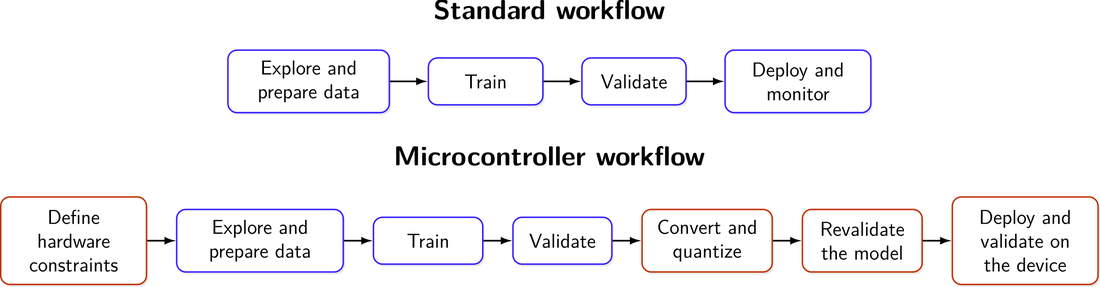

| **Question** | Does an int8 neural network, running on an ESP32, keep the performance of its float32 version? |
|---|---|
| **Scope** | Classification of 8×8 digits with a small dense network, quantized to int8 after training and deployed on an ESP32. |
| **General objective** | Identify the design decisions and technical trade-offs involved in bringing a neural network to a microcontroller, using int8 quantization as a case study. |
| **Specific objectives** | 1. Identify the technical trade-offs of quantizing and deploying on a microcontroller.<br>2. Compare accuracy, size and latency between float32 and int8.<br>3. Validate the quantized model on the ESP32. |


> **Note:** float32 and int8 were chosen for simplicity and according to the objectives of this presentation. Other numeric formats used in practice, such as bf16, fp8 or int4, are out of scope.

### Environment

In [ ]:
!pip install -q ai-edge-litert torchinfo

In [ ]:
import time, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import torch._dynamo
import tensorflow as tf
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter

tf.get_logger().setLevel("ERROR")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); tf.random.set_seed(SEED)
F32, I8, NAVY = "#351EFF", "#C23000", "#0B1A78"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10})

## 1. Define the hardware constraints

| ESP32-D0WD-V3 | Value |
|---|---|
| Processor | Xtensa LX6 · 2 cores at 240 MHz |
| Free RAM | **~324 KB** (measured in Arduino IDE) |
| Flash | **4 MB** |
| Floating point | Yes, single precision |

In [ ]:
BUDGET = {"RAM (KB)": 324, "Flash (KB)": 4096}

## 2. Explore and prepare the data

*Optical Recognition of Handwritten Digits* (Alpaydin and Kaynak, 1998, UCI): 1,797 binary 32×32 images reduced to 8×8 (values 0–16). Preparation: flatten to 64 values, normalize to [0, 1] and split, stratified, into training, validation and test sets.

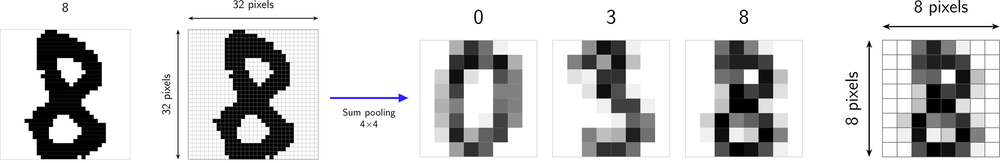

In [ ]:
digits = load_digits()
X = (digits.data / 16.0).astype(np.float32)
y = digits.target.astype(np.int64)

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.20, stratify=y_tmp, random_state=SEED)
print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

fig, ax = plt.subplots(1, 10, figsize=(10, 1.3))
for d, a in enumerate(ax):
    a.imshow(digits.images[np.where(y == d)[0][0]], cmap="gray_r"); a.set_title(d); a.axis("off")
plt.show()

## 3. Training

Dense network (MLP) **64 → 32 → 16 → 10** with ReLU, trained in PyTorch (float32).

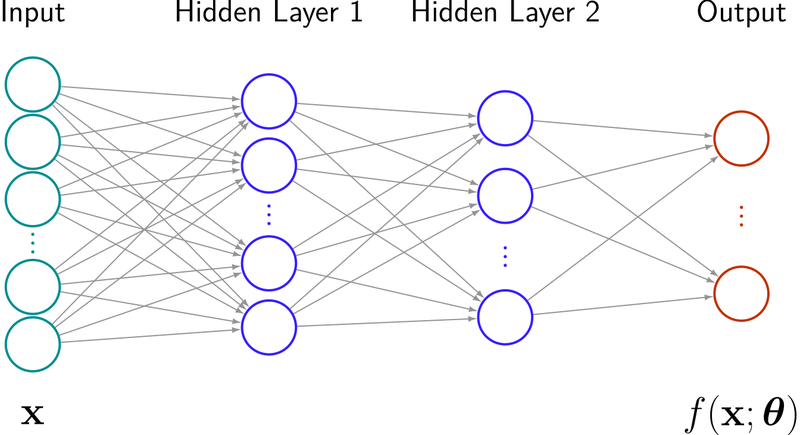

In [ ]:
model = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 10))
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params} -> {n_params*4/1024:.2f} KB in float32")

Xtr, ytr = torch.from_numpy(X_train), torch.from_numpy(y_train)
Xva, yva = torch.from_numpy(X_val), torch.from_numpy(y_val)
Xte, yte = torch.from_numpy(X_test), torch.from_numpy(y_test)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
opt, loss_fn = torch.optim.Adam(model.parameters(), lr=1e-2), nn.CrossEntropyLoss()

hist = {"loss": [], "val": []}
for epoch in range(60):
    model.train()
    for xb, yb in loader:
        opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        hist["loss"].append(loss_fn(model(Xtr), ytr).item())
        hist["val"].append((model(Xva).argmax(1) == yva).float().mean().item())

In [ ]:
from torchinfo import summary
print(summary(model, input_size=(1, 64), col_names=["output_size", "num_params"], verbose=0))
pd.DataFrame([(n, tuple(p.shape), p.numel(), p.min().item(), p.max().item()) for n, p in model.named_parameters()],
             columns=["parameter", "shape", "count", "min", "max"]).round(3)

## 4. Validation

In [ ]:
with torch.no_grad():
    acc_torch = (model(Xte).argmax(1) == yte).float().mean().item()

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist["loss"], color=F32); ax[0].set(title="Training loss", xlabel="epoch")
ax[1].plot(np.array(hist["val"]) * 100, color=F32); ax[1].set(title="Validation accuracy (%)", xlabel="epoch")
plt.tight_layout(); plt.show()
print(f"float32 test accuracy: {acc_torch:.2%}")

## 5. Convert and quantize

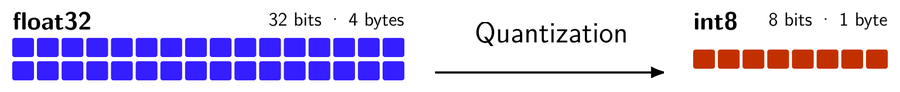

$$q = \mathrm{round}\left(\frac{x}{s}\right) + z \qquad x \approx s\,(q - z)$$

$s$: scale · $z$: zero point. The LiteRT converter takes Keras models, so the PyTorch weights are copied into an identical Keras network (transposing each matrix). int8 quantization uses 200 training images for **calibration** and a single scale per layer (not per neuron), which is compatible with LiteRT for Microcontrollers.

In [ ]:
keras_model = tf.keras.Sequential([tf.keras.Input(shape=(64,)),
    tf.keras.layers.Dense(32, activation="relu"), tf.keras.layers.Dense(16, activation="relu"), tf.keras.layers.Dense(10)])
torch_linears = [m for m in model if isinstance(m, nn.Linear)]
for k, t in zip(keras_model.layers, torch_linears):
    k.set_weights([t.weight.detach().numpy().T, t.bias.detach().numpy()])

def convert(int8=False):
    conv = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    if int8:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = lambda: ([X_train[i:i+1]] for i in range(200))
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = conv.inference_output_type = tf.int8
        conv._experimental_disable_per_channel_quantization_for_dense_layers = True
    with contextlib.redirect_stdout(io.StringIO()):
        return conv.convert()

tflite_f32, tflite_i8 = convert(), convert(int8=True)
open("model_int8.tflite", "wb").write(tflite_i8)
print(f"LiteRT float32: {len(tflite_f32)/1024:.2f} KB | LiteRT int8: {len(tflite_i8)/1024:.2f} KB")

## 6. Revalidate the model

The int8 model is **a different model**: accuracy, size and latency are measured again. *Latency here is measured on the Colab CPU; the relevant figure is the one measured on the ESP32.*

In [ ]:
def evaluate(model_bytes, X):
    itp = Interpreter(model_content=model_bytes); itp.allocate_tensors()
    inp, out = itp.get_input_details()[0], itp.get_output_details()[0]
    preds, t0 = [], time.perf_counter()
    for x in X:
        x = x[None, :]
        if inp["dtype"] == np.int8:
            s, z = inp["quantization"]; x = np.clip(np.round(x / s) + z, -128, 127).astype(np.int8)
        itp.set_tensor(inp["index"], x); itp.invoke()
        preds.append(itp.get_tensor(out["index"])[0].argmax())
    return np.array(preds), (time.perf_counter() - t0) / len(X) * 1e6

p32, lat32 = evaluate(tflite_f32, X_test)
p8,  lat8  = evaluate(tflite_i8,  X_test)
n_w = sum(m.weight.numel() for m in torch_linears); n_b = sum(m.bias.numel() for m in torch_linears)

res = pd.DataFrame({
    "float32": [(p32 == y_test).mean()*100, len(tflite_f32)/1024, n_params*4/1024, lat32],
    "int8":    [(p8 == y_test).mean()*100,  len(tflite_i8)/1024,  (n_w + n_b*4)/1024, lat8]},
    index=["Accuracy (%)", "File (KB)", "Parameters (KB)", "Colab latency (µs)"]).round(2)
res["int8 / float32"] = (res["int8"] / res["float32"]).round(2)
print(f"Matching predictions: {(p32 == p8).mean():.2%}")
res

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, row in zip(ax, ["Accuracy (%)", "File (KB)", "Colab latency (µs)"]):
    v = res.loc[row, ["float32", "int8"]]
    b = a.bar(["float32", "int8"], v, color=[F32, I8], width=0.55)
    a.bar_label(b, fmt="%.1f", padding=3, fontweight="bold"); a.set_title(row); a.set_yticks([])
    a.spines["left"].set_visible(False); a.set_ylim(0, v.max() * 1.2)
plt.suptitle("float32 vs int8", fontweight="bold", color=NAVY); plt.tight_layout(); plt.show()

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, p, c, t in zip(ax, [p32, p8], ["Blues", "Oranges"], ["float32", "int8"]):
    a.imshow(confusion_matrix(y_test, p), cmap=c)
    for (i, j), v in np.ndenumerate(confusion_matrix(y_test, p)):
        if v: a.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if i == j else "black")
    a.set(title=f"Confusion matrix · {t}  ({(p == y_test).mean():.1%})", xlabel="predicted", ylabel="true",
          xticks=range(10), yticks=range(10))
plt.tight_layout(); plt.show()

dif = np.where(p32 != p8)[0]
if len(dif):
    fig, ax = plt.subplots(1, len(dif[:6]), figsize=(2 * len(dif[:6]), 2.3), squeeze=False)
    for a, i in zip(ax[0], dif[:6]):
        a.imshow(X_test[i].reshape(8, 8), cmap="gray_r"); a.axis("off")
        a.set_title(f"true {y_test[i]}\nf32 {p32[i]} · int8 {p8[i]}", fontsize=9)
    plt.suptitle("Images where float32 and int8 disagree", fontweight="bold", color=NAVY); plt.tight_layout(); plt.show()

In [ ]:
itp = Interpreter(model_content=tflite_i8); itp.allocate_tensors()
w_f = keras_model.layers[0].get_weights()[0].T
det = next(d for d in itp.get_tensor_details() if d["dtype"] == np.int8 and tuple(d["shape"]) == w_f.shape)
w_q = itp.get_tensor(det["index"]).astype(np.float32)
w_r = w_q * det["quantization_parameters"]["scales"].reshape(-1, 1)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].hist(w_f.ravel(), bins=40, color=F32); ax[0].set(title="float32 weights (layer 1)")
ax[1].hist(w_q.ravel(), bins=40, color=I8); ax[1].set(title="int8 weights (integers)")
ax[2].hist((w_f - w_r).ravel(), bins=40, color=NAVY); ax[2].set(title="Rounding error")
plt.tight_layout(); plt.show()
print(f"Mean absolute error: {np.abs(w_f - w_r).mean():.5f}")

## 7. Deploy and validate on the device

The ESP32 does not read `.tflite` files: the model is compiled into the program as a C array (stored in Flash). The actual RAM (*tensor arena*), latency and accuracy are measured on the board.

In [ ]:
act = sum(int(np.prod(d["shape"])) for d in itp.get_tensor_details() if d["dtype"] == np.int8 and d["shape"][0] == 1)
print(pd.DataFrame({"Estimated use (KB)": [act/1024, len(tflite_i8)/1024], "Available (KB)": list(BUDGET.values())},
                   index=["RAM (activations)", "Flash (model)"]).round(2))

def to_c_header(data, name):
    return (f"#pragma once\nalignas(16) const unsigned char {name}[] = {{{', '.join(f'0x{b:02x}' for b in data)}}};\n"
            f"const unsigned int {name}_len = {len(data)};\n")
open("model_int8.h", "w").write(to_c_header(tflite_i8, "g_model"))

s, z = itp.get_input_details()[0]["quantization"]; N = 20
Xq = np.clip(np.round(X_test[:N] / s) + z, -128, 127).astype(np.int8)
with open("test_samples.h", "w") as f:
    f.write(f"#pragma once\nconst int kNumSamples = {N};\nconst int8_t kSamples[{N}][64] = {{\n")
    f.write(",\n".join("  {" + ", ".join(map(str, r)) + "}" for r in Xq) + "\n};\n")
    f.write(f"const int kLabels[{N}] = {{{', '.join(map(str, y_test[:N]))}}};\n")

try:
    from google.colab import files
    for f in ["model_int8.h", "test_samples.h", "model_int8.tflite"]: files.download(f)
except ImportError:
    print("Generated files: model_int8.h, test_samples.h, model_int8.tflite")